# SDC convergence study on the Dahlquist problem

This notebook studies the accuracy of **Spectral Deferred Correction (SDC)** generated with the
[`qmat`](https://github.com/parallel-in-time/qmat) library, applied to the Dahlquist test problem.

For each configuration, it:

1. builds a **collocation problem** (`Collocation`) with $M$ nodes, producing the integration matrix $Q$,
2. generates the **sweep matrices** $Q_\Delta$ for a chosen sweep type and number of sweeps $K$
   (`genQDeltaCoeffs`),
3. integrates the test problem with `solveDahlquistSDC` for a range of time steps $\Delta t$,
4. plots the $L_\infty$ error versus $\Delta t$ on a log-log scale (the slope is the observed order of
   convergence).

The sweep types compared below are **BE** (backward Euler sweeps) and the optimized
**MIN-SR** variants **MIN-SR-NS**, **MIN-SR-S** and **MIN-SR-FLEX**, all with
$M=3$ Legendre Radau-right nodes and $K=1 \dots 4$ sweeps.

## Test problem: the Dahlquist equation

The Dahlquist equation is the linear scalar ODE

$$u' = \lambda u, \qquad u(0) = u_0, \qquad u(t) = u_0 e^{\lambda t}.$$

Here $\lambda = i$ is purely imaginary, so the exact solution stays on the unit circle and the
integration covers one full rotation over $t_{end} = 2\pi$. It is the standard test problem for
measuring the accuracy of time integrators, since the exact solution is known analytically.

In [1]:
import numpy as np

u0 = 1
lam = 1j
tEnd = 2*np.pi

## Convergence runs

`convergenceRuns` performs one full convergence study for a given combination of
number of nodes, node type, quadrature type, number of sweeps and sweep type:

- `Collocation(nNodes, nodeType, quadType)` generates the collocation nodes and the
  corresponding integration matrix $Q$,
- `genQDeltaCoeffs(sweepType, nSweeps, qGen=qGen)` produces the $Q_\Delta$ matrices (one per sweep)
  used as a preconditioner in the SDC iteration,
- `solveDahlquistSDC(...)` integrates the Dahlquist problem over `nSteps` uniform steps,
- the $L_\infty$ error against the exact solution is plotted versus $\Delta t$ in a log-log scale.

With `verbose=False` the matrices are not printed, so several runs can be compared without
flooding the output.

In [2]:

import matplotlib.pyplot as plt

from qmat import genQDeltaCoeffs
from qmat.qcoeff.collocation import Collocation
from qmat.utils.sdc import solveDahlquistSDC

python_print = print

def convergenceRuns(nNodes, nodeType, quadType, nSweeps, sweepType, verbose=True):

    print = python_print if verbose else lambda *args: args

    qGen = Collocation(nNodes, nodeType, quadType)
    print(f"Collocation M{nNodes}-{nodeType}-{quadType}")
    print(f" -- nodes : {qGen.nodes}")
    print(" -- Q matrix :")
    print(qGen.Q)

    QDelta = genQDeltaCoeffs(sweepType, nSweeps, qGen=qGen)
    print(f"SDC K{nSweeps}-{sweepType}")
    for k in range(nSweeps):
        print(f" -- QDelta matrix sweep {k+1} :")
        print(QDelta[k])

    nStepsVals = np.array([10, 20, 50, 100, 200, 500, 1000, 2000])
    errors = []

    for nSteps in nStepsVals:
        uNum = solveDahlquistSDC(lam, u0, tEnd, nSteps, nSweeps, qGen.Q, QDelta)
        times = np.linspace(0, tEnd, nSteps+1)
        uExact = u0 * np.exp(lam*times)
        errors.append(np.linalg.norm(uNum-uExact, ord=np.inf))
    errors = np.array(errors)

    label = f"M{nNodes}-{nodeType}-{quadType}_K{nSweeps}-{sweepType}"
    plt.loglog(tEnd/nStepsVals, errors, "o-", label=label)
    plt.xlabel(r"$\Delta{t}$"); plt.ylabel(r"Error $(L_\infty)$"); plt .grid(True)
    plt.legend()
    python_print(f"Errors {label} :")
    python_print(errors)

## Sweep type: backward Euler (BE)

Reference case: $K$ sweeps using backward Euler substeps. Each sweep typically gains one order
of accuracy, until the collocation order is reached.

Errors M3-LEGENDRE-RADAU-RIGHT_K1-BE :
[0.53189579 0.31837071 0.14262607 0.07409804 0.0377678  0.0152825
 0.00767072 0.00384275]
Errors M3-LEGENDRE-RADAU-RIGHT_K2-BE :
[9.40215703e-02 2.54085169e-02 4.14704698e-03 1.03942763e-03
 2.60016195e-04 4.16095441e-05 1.04026308e-05 2.60067290e-06]
Errors M3-LEGENDRE-RADAU-RIGHT_K3-BE :
[1.30026824e-02 1.68500238e-03 1.08838198e-04 1.36228155e-05
 1.70342314e-06 1.09029444e-07 1.36289523e-08 1.70357082e-09]
Collocation M3-LEGENDRE-RADAU-RIGHT
 -- nodes : [0.15505103 0.64494897 1.        ]
 -- Q matrix :
[[ 0.19681548 -0.06553543  0.02377097]
 [ 0.39442431  0.29207341 -0.04154875]
 [ 0.37640306  0.51248583  0.11111111]]
SDC K4-BE
 -- QDelta matrix sweep 1 :
[[0.15505103 0.         0.        ]
 [0.15505103 0.48989795 0.        ]
 [0.15505103 0.48989795 0.35505103]]
 -- QDelta matrix sweep 2 :
[[0.15505103 0.         0.        ]
 [0.15505103 0.48989795 0.        ]
 [0.15505103 0.48989795 0.35505103]]
 -- QDelta matrix sweep 3 :
[[0.15505103 0.    

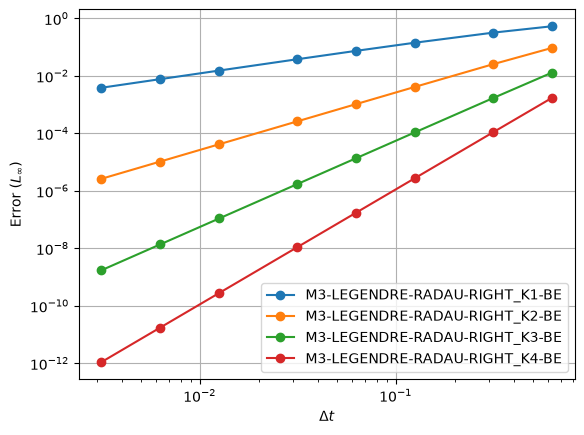

In [3]:
for nSweeps in range(1, 5):
    convergenceRuns(3, "LEGENDRE", "RADAU-RIGHT", nSweeps, "BE", verbose=(nSweeps==4))

## Sweep type: MIN-SR-NS

Minion's *min-SR* sweeps use optimized $Q_\Delta$ matrices designed to increase the SDC
order faster than plain backward Euler sweeps. The **NS** variant uses non-separable
(lower-triangular, dense) $Q_\Delta$ matrices.

Errors M3-LEGENDRE-RADAU-RIGHT_K1-MIN-SR-NS :
[0.87823895 0.3856225  0.14048114 0.06799288 0.03344384 0.01324632
 0.00660142 0.00329528]
Errors M3-LEGENDRE-RADAU-RIGHT_K2-MIN-SR-NS :
[7.46393371e-03 9.10286174e-04 5.78100369e-05 7.21816813e-06
 9.02019484e-07 5.77247191e-08 7.21539395e-09 9.01819443e-10]
Errors M3-LEGENDRE-RADAU-RIGHT_K3-MIN-SR-NS :
[6.09670408e-04 3.78892373e-05 9.67655702e-07 6.04559518e-08
 3.77814073e-09 9.67180660e-11 6.04818871e-12 3.93764546e-13]
Collocation M3-LEGENDRE-RADAU-RIGHT
 -- nodes : [0.15505103 0.64494897 1.        ]
 -- Q matrix :
[[ 0.19681548 -0.06553543  0.02377097]
 [ 0.39442431  0.29207341 -0.04154875]
 [ 0.37640306  0.51248583  0.11111111]]
SDC K4-MIN-SR-NS
 -- QDelta matrix sweep 1 :
[[0.05168368 0.         0.        ]
 [0.         0.21498299 0.        ]
 [0.         0.         0.33333333]]
 -- QDelta matrix sweep 2 :
[[0.05168368 0.         0.        ]
 [0.         0.21498299 0.        ]
 [0.         0.         0.33333333]]
 -- QDelta matrix 

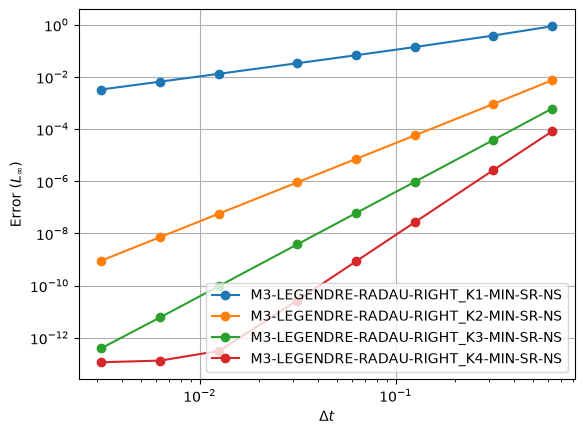

In [4]:
for nSweeps in range(1, 5):
    convergenceRuns(3, "LEGENDRE", "RADAU-RIGHT", nSweeps, "MIN-SR-NS", verbose=(nSweeps==4))

## Sweep type: MIN-SR-S

The **S** (separable) variant of the min-SR sweeps restricts $Q_\Delta$ to diagonal
matrices, which makes each sweep cheaper but may reduce the achievable order compared to
MIN-SR-NS.

Errors M3-LEGENDRE-RADAU-RIGHT_K1-MIN-SR-S :
[0.21397591 0.06369173 0.0170106  0.00769348 0.00373544 0.00148064
 0.00073919 0.00036942]
Errors M3-LEGENDRE-RADAU-RIGHT_K2-MIN-SR-S :
[4.22016639e-02 8.44831031e-03 1.21052598e-03 2.96911666e-04
 7.38623278e-05 1.18014893e-05 2.94978251e-06 7.37408750e-07]
Errors M3-LEGENDRE-RADAU-RIGHT_K3-MIN-SR-S :
[7.20923976e-03 7.58129907e-04 4.45089587e-05 5.48211117e-06
 6.82660784e-07 4.36433954e-08 5.45461368e-09 6.81567855e-10]
Collocation M3-LEGENDRE-RADAU-RIGHT
 -- nodes : [0.15505103 0.64494897 1.        ]
 -- Q matrix :
[[ 0.19681548 -0.06553543  0.02377097]
 [ 0.39442431  0.29207341 -0.04154875]
 [ 0.37640306  0.51248583  0.11111111]]
SDC K4-MIN-SR-S
 -- QDelta matrix sweep 1 :
[[0.10404994 0.         0.        ]
 [0.         0.33281275 0.        ]
 [0.         0.         0.48129014]]
 -- QDelta matrix sweep 2 :
[[0.10404994 0.         0.        ]
 [0.         0.33281275 0.        ]
 [0.         0.         0.48129014]]
 -- QDelta matrix swee

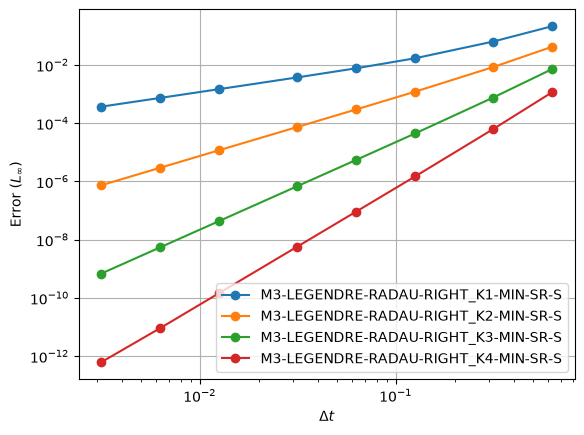

In [5]:
for nSweeps in range(1, 5):
    convergenceRuns(3, "LEGENDRE", "RADAU-RIGHT", nSweeps, "MIN-SR-S", verbose=(nSweeps==4))

## Sweep type: MIN-SR-FLEX

The **FLEX** variant allows a flexible ordering of the nodes inside each sweep, generalizing
the fixed sweeps of the NS and S variants.

Errors M3-LEGENDRE-RADAU-RIGHT_K1-MIN-SR-FLEX :
[0.86006386 0.62189544 0.32521015 0.17896839 0.09395842 0.03870766
 0.01954546 0.00982103]
Errors M3-LEGENDRE-RADAU-RIGHT_K2-MIN-SR-FLEX :
[1.65289859e-01 4.88626205e-02 8.20203164e-03 2.06315879e-03
 5.16533583e-04 8.26774438e-05 2.06704812e-05 5.16768975e-06]
Errors M3-LEGENDRE-RADAU-RIGHT_K3-MIN-SR-FLEX :
[1.47063762e-02 1.56627847e-03 8.92598314e-05 1.09094798e-05
 1.35562065e-06 8.66136966e-08 1.08239817e-08 1.35280760e-09]
Collocation M3-LEGENDRE-RADAU-RIGHT
 -- nodes : [0.15505103 0.64494897 1.        ]
 -- Q matrix :
[[ 0.19681548 -0.06553543  0.02377097]
 [ 0.39442431  0.29207341 -0.04154875]
 [ 0.37640306  0.51248583  0.11111111]]
SDC K4-MIN-SR-FLEX
 -- QDelta matrix sweep 1 :
[[0.15505103 0.         0.        ]
 [0.         0.64494897 0.        ]
 [0.         0.         1.        ]]
 -- QDelta matrix sweep 2 :
[[0.07752551 0.         0.        ]
 [0.         0.32247449 0.        ]
 [0.         0.         0.5       ]]
 -- QDelta

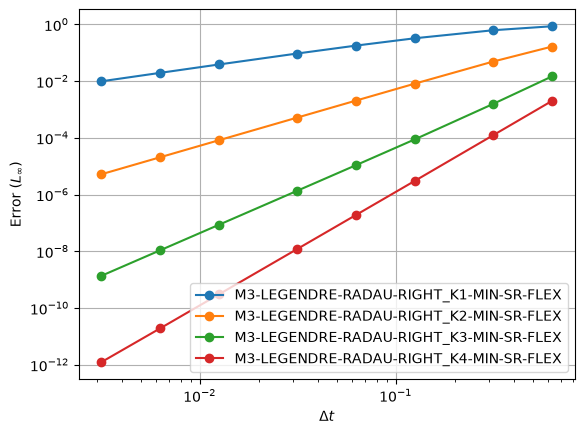

In [6]:
for nSweeps in range(1, 5):
    convergenceRuns(3, "LEGENDRE", "RADAU-RIGHT", nSweeps, "MIN-SR-FLEX", verbose=(nSweeps==4))

## What to look at

Each curve shows the $L_\infty$ error versus $\Delta t$; the slope of a curve is the observed
order of convergence. Comparing the plots above shows how, for a fixed number of sweeps $K$,
the different sweep types achieve different orders: the optimized MIN-SR sweeps generally
converge faster with $K$ than plain backward Euler sweeps, at the price of denser or less
conventional $Q_\Delta$ matrices.